In [1]:
import torch 
import torch.nn as nn 
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np 
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt 
import time 
import os 
import copy

plt.ion() # interactive mode

In [2]:
device = torch.device("mps:0")

In [3]:
# data augmentation and normalization 
# just normalization for validation 

import torch.utils
import torch.utils.data
import torch.utils.data.dataloader


data_transforms = { 
    'train' : transforms.Compose([
        transforms.RandomResizedCrop(224), 
        transforms.RandomHorizontalFlip(), 
        transforms.ToTensor(), 
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]), 
    'val': transforms.Compose([
        transforms.Resize(256), 
        transforms.CenterCrop(224), 
        transforms.ToTensor(), 
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=4) for x in ['train', 'val']}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}

class_names = image_datasets['train'].classes

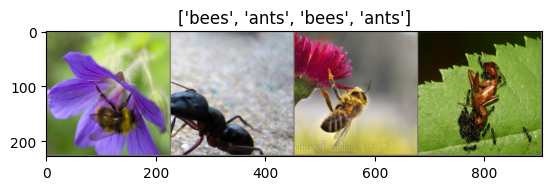

In [4]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])


In [7]:
def train_model(model, criterion, optimizer, scheduler, num_epochs = 25): 
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict()) 
    best_acc = 0.0

    for epoch in range(num_epochs): 
        print(f"Epoch {epoch}/{num_epochs - 1}")
        print('-' * 10)

        # each epoch has a training and validation phase 
        for phase in ['train', 'val']: 
            if phase == 'train': 
                model.train()
            else: 
                model.eval()
            
            running_loss = 0.0
            running_corrects = 0

            # iterate over data 
            for inputs, labels in dataloaders[phase]: 
                inputs = inputs.to(device) 
                labels = labels.to(device) 

                # forward 
                with torch.set_grad_enabled(phase == 'train'): 
                    outputs = model(inputs) 
                    _, preds = torch.max(outputs, 1) 
                    loss = criterion(outputs, labels) 

                    # backward + optimize only if in training phase 
                    if phase == 'train': 
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.float() / dataset_sizes[phase]

            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc: 
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()
    
    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Best val Acc: {best_acc:4f}")

    model.load_state_dict(best_model_wts) 
    return model 

In [8]:
# import pretrained model 
model = models.resnet18(pretrained = True) 

# get number of input features in the last layer 
num_ftrs = model.fc.in_features

# swap last layer to have 2 output classes
model.fc = nn.Linear(num_ftrs, 2)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr = 0.001)

# scheduler, updates learning rate, every 7 epochs multiply lr by 0.1
step_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

# for epoch in range(100): 
    # 1. train + optimizer.step()
    # 2. evaluate + scheduler.step() - updates lr after every 7 epochs

model = train_model(model, criterion, optimizer, scheduler=step_lr_scheduler, num_epochs=25)


/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 0/24
----------
train Loss: 0.6392 Acc: 0.6270
val Loss: 0.4618 Acc: 0.7712

Epoch 1/24
----------
train Loss: 0.5178 Acc: 0.7541
val Loss: 0.3101 Acc: 0.9281

Epoch 2/24
----------
train Loss: 0.4421 Acc: 0.8033
val Loss: 0.2485 Acc: 0.9412

Epoch 3/24
----------
train Loss: 0.3889 Acc: 0.8320
val Loss: 0.2133 Acc: 0.9412

Epoch 4/24
----------
train Loss: 0.3902 Acc: 0.8156
val Loss: 0.2032 Acc: 0.9412

Epoch 5/24
----------
train Loss: 0.3622 Acc: 0.8484
val Loss: 0.1960 Acc: 0.9412

Epoch 6/24
----------
train Loss: 0.4308 Acc: 0.7746
val Loss: 0.1894 Acc: 0.9477

Epoch 7/24
----------
train Loss: 0.3435 Acc: 0.8525
val Loss: 0.1919 Acc: 0.9477

Epoch 8/24
----------
train Loss: 0.3802 Acc: 0.8238
val Loss: 0.1942 Acc: 0.9412

Epoch 9/24
----------
train Loss: 0.3153 Acc: 0.8893
val Loss: 0.1782 Acc: 0.9542

Epoch 10/24
----------
train Loss: 0.4173 Acc: 0.7910
val Loss: 0.1780 Acc: 0.9542

Epoch 11/24
----------
train Loss: 0.2794 Acc: 0.8852
val Loss: 0.1825 Acc: 0.9412

Ep

In [9]:
# freezing beginning layers -> faster training 
model = models.resnet18(pretrained = True) 

# freeze all layers
for param in model.parameters(): 
    param.requires_grad = False

# create new layer with gradient enabled by default 
num_ftrs = model.fc.in_features # input features to the last layer

model.fc = nn.Linear(num_ftrs, 2) # 2 output classes
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr = 0.001)

# scheduler 
step_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
model = train_model(model, criterion, optimizer, scheduler = step_lr_scheduler, num_epochs=25)

Epoch 0/24
----------


KeyboardInterrupt: 